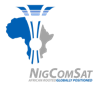 &nbsp;&nbsp; 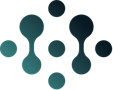

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Publica-AI/nigcomsat-ai-developer/blob/jasons-restructure/Jasons-Restructure/week-2/day-2-does-today-remember-yesterday/2-exercise/W2D2-exercise.ipynb)

# 🧠 Week 2 · Day 2: Does Today Remember Yesterday?

**Today:** measure how much a series remembers its own past (**autocorrelation**), read a **correlogram** to find the season yourself, and catch a **fake correlation** before it fools your boss.

| Symbol | Means |
|---|---|
| 📖 | Read this |
| ▶️ | Run the cell below (click it, then press **Shift + Enter**) |
| ✍️ | Your turn: replace every `___` with your answer |
| ✅ / ❌ | The check tells you if you got it right, with a hint if not |
| 🌶️ | Bonus task for fast finishers |

> ## ⚠️ Do this FIRST: **File → Save a copy in Drive**
> Work in your copy (the new tab), not the original.

**Rule book:** keep `W2D2-rulebook.pdf` open next to you.

## ▶️ STEP 0: Set up (run this once, every time you open the notebook)

Click the cell below and press **Shift + Enter**. Wait for `✅ Ready!`. If Colab says *"This notebook was not authored by Google"*, click **Run anyway**.

In [ ]:
#@title 🚀 STEP 0 · Run me first (click the ▶ button on the left of this cell) { display-mode: "form" }
import sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold",
                     "axes.prop_cycle": plt.cycler(color=["#0A5DB4", "#C77700", "#008C7E"])})

IN_COLAB = "google.colab" in sys.modules
RAW = "https://raw.githubusercontent.com/Publica-AI/nigcomsat-ai-developer/main/Time-series"
DATA_HOME = {'additive_multiplicative_demo': 'week-03', 'bandwidth_throughput_daily': 'week-03', 'ka_band_availability_daily': 'week-03', 'ka_band_availability_monthly': 'week-03', 'link_margin_hourly_aug2025': 'week-03', 'noc_tickets_daily': 'week-03', 'noc_tickets_weekly': 'week-03', 'transponder_utilisation_monthly': 'week-03', 'vsat_uptime_by_region_weekly': 'week-03', 'rf_link_quality_hourly': 'week-03', 'bus_power_telemetry_hourly': 'week-04', 'battery_health_daily': 'week-04', 'twta_thermal_daily': 'week-04', 'telemetry_anomaly_labels': 'week-04', 'bus_telemetry_multivariate_hourly': 'week-05', 'anomaly_labels_week5': 'week-05', 'degradation_assets_daily': 'week-06', 'degradation_thresholds': 'week-06', 'ops_tickets_weekly': 'week-06'}

def data_path(name, week=None):
    """Download a course CSV once and return where it is saved.
    week: which original folder to use, e.g. "week-03" (two files exist in both week-03 and week-04).
    If you uploaded the file yourself (Files panel), that copy is used instead."""
    uploaded = Path(f"{name}.csv")
    if uploaded.exists():
        return uploaded
    week = week or DATA_HOME[name]
    local = Path("course_data") / week / f"{name}.csv"
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{RAW}/{week}/data/{name}.csv", local)
    return local

___ = None          # this is "the blank". Replace every ___ with your answer.
SCORE = {}

def _blank(x):
    return x is None or (isinstance(x, tuple) and any(v is None for v in x))

def check(task, answer):
    """Marks one task. Prints ✅ or ❌ with a hint."""
    if _blank(answer):
        print("✍️  Fill in the blank first: replace ___ with your answer, then run the cell again.")
        return
    try:
        ok, good, hint = CHECKS[task](answer)
    except Exception as e:
        ok, good, hint = False, "", f"{HINTS.get(task, 'Read the task again.')}  (Python said: {type(e).__name__})"
    SCORE[task] = ok
    print(("✅ " + good) if ok else ("❌ Not yet. Hint: " + hint))

def scoreboard():
    got = sum(SCORE.values())
    print(f"You have {got} of {len(CHECKS)} tasks correct.")
    print("🏆 Oya, you don finish! Mad o!" if got == len(CHECKS) else "💪 Keep going: scroll up and fix the ❌ ones.")

# ---- today's checks ----
def make_sales():
    """MADE-UP weekly sales at one Lagos market for a year (an illustration, not course data).
    Both rise toward December for their own reasons: festive suya, and generators for the holidays."""
    rng = np.random.default_rng(11)
    t = np.arange(52)
    idx = pd.RangeIndex(1, 53, name="week")
    suya = pd.Series(120 + 3.0 * t + rng.normal(0, 8, 52), index=idx, name="suya_sticks").round(1)
    gens = pd.Series(30 + 0.9 * t + rng.normal(0, 3, 52), index=idx, name="generators_sold").round(1)
    return suya, gens


def _bw():
    return pd.read_csv(data_path("bandwidth_throughput_daily"), parse_dates=["date"], index_col="date").asfreq("D")["throughput_gbps"]

def _near(x, want, tol):
    return abs(float(x) - float(want)) <= tol

def _c_a2(x):
    s = _bw()
    ok = isinstance(x, pd.Series) and len(x) == len(s) and np.isnan(x.iloc[0]) and np.allclose(x.iloc[1:].values, s.iloc[:-1].values)
    return ok, "Yes! Every value slid down one day. Day 1 has no yesterday, so it's NaN.", \
        "Use s.shift(1): it pushes the whole column down by one step."

def _c_a3(x):
    v = _bw().autocorr(lag=1)
    return _near(x, v, 0.005), f"r = {v:.2f}. Today remembers yesterday… a little.", "Try s.autocorr(lag=1)"

def _c_a4(x):
    v = _bw().autocorr(lag=7)
    return _near(x, v, 0.005), f"r = {v:.2f}! Last week's same day is almost a perfect copy. Mondays look like Mondays.", \
        "Same as A3, but lag=7."

def _c_b2(x):
    return int(x) == 7, "Period 7: spikes at 7, 14, 21, 28 = the working week. 💼", \
        "Look at WHERE the tall bars are (ignore lag 0). What's the gap between them?"

def _c_b3(x):
    return float(x) == 1.0, "Lag 0 is always 1: the series compared with itself. Ignore that bar.", \
        "What do you get if you compare anything with an exact copy of itself?"

def _c_b4(x):
    return int(x) == 7, "7 again: even faults rest at the weekend. 😄", "Same idea as B2: the gap between the tall spikes."

def _c_b5(x):
    return int(x) == 24, "24 hours: the eclipse hits at 21:00 every day, so the battery repeats daily. 🔋", \
        "This data is HOURLY. Where is the first big spike after lag 0?"

def _c_b6(x):
    return str(x).strip().lower() == "trend", "Trend! High bars that fade slowly = every month looks like the last.", \
        "Choose: season, trend or noise. No spikes, slow fade…"

def _c_b7(x):
    s = _bw(); v = (s - s.shift(7)).abs().mean()
    return _near(x, v, 0.0005), f"{v:.3f} Gbps: about {(s - s.shift(1)).abs().mean() / v:.0f}× smaller than 'same as yesterday'. Free forecast! 🎁", \
        "Copy the mae_yesterday line, but shift by 7."

def _c_c2(x):
    suya, gens = make_sales(); v = suya.corr(gens)
    return _near(x, v, 0.005), f"r = {v:.2f}. Wow, suya sells generators?! 🤔 (Hold on…)", "Use suya.corr(gens)"

def _c_c3(x):
    suya, gens = make_sales(); v = suya.diff().corr(gens.diff())
    return _near(x, v, 0.005), f"r = {v:.2f}. Collapsed! It was only shared trend (Detty December). 🎉", \
        "Use suya.diff().corr(gens.diff())"

def _c_c4(x):
    tw = pd.read_csv(data_path("twta_thermal_daily", week="week-03"), parse_dates=["date"], index_col="date").asfreq("D")
    raw = tw["twta_temp_c"].corr(tw["rf_drive_pct"]); dif = tw["twta_temp_c"].diff().corr(tw["rf_drive_pct"].diff())
    return _near(x[0], raw, 0.005) and _near(x[1], dif, 0.005), \
        f"{raw:.2f} → {dif:.2f}: it drops but survives. Part shared trend, part real physics (more drive → more heat).", \
        "Same two lines as C2 and C3, but with twta['twta_temp_c'] and twta['rf_drive_pct']."

def _c_bonus(x):
    return 360 <= int(x) <= 370, f"Lag {int(x)}: about a year! The rainy season comes back every 365 days. 🌧️", \
        "acf_vals[300:].argmax() gives the position INSIDE the slice. Add 300 back."

CHECKS = {"A2": _c_a2, "A3": _c_a3, "A4": _c_a4, "B2": _c_b2, "B3": _c_b3, "B4": _c_b4, "B5": _c_b5,
          "B6": _c_b6, "B7": _c_b7, "C2": _c_c2, "C3": _c_c3, "C4": _c_c4, "BONUS": _c_bonus}
HINTS = {"C4": "Give two numbers: twta_raw and twta_diff.", "BONUS": "acf_vals[300:].argmax() + 300"}

print(f"✅ Ready! pandas {pd.__version__} · running in {'Google Colab' if IN_COLAB else 'Jupyter'}. Scroll down and let's go 🚀")


---
# Part A: How much does today remember? (20 min) 🧠

**The data:** `bandwidth_throughput_daily.csv`: total data carried by the Nigeria spot beam each day, in Gbps (gigabits per second), for two years. Synthetic, built to behave like NigComSat-1R.

### A1 ▶️ Load it and look at 8 weeks
The same 3-line recipe from Day 1. Look at the chart: what happens every weekend?

In [ ]:
bw = pd.read_csv(data_path("bandwidth_throughput_daily"), parse_dates=["date"], index_col="date").asfreq("D")
s = bw["throughput_gbps"]          # one column = one series. We'll call it s

s.iloc[:56].plot(title="8 weeks of throughput: dips every weekend", marker="o", ms=3)
plt.ylabel("Gbps")
plt.show()

### A2 ✍️ Make "yesterday"
A **lag** is a copy of the series pushed back in time. `s.shift(1)` slides every value down one row, so each day sits next to **yesterday's** value.
Create the lag-1 copy.

In [ ]:
yesterday = ___

check("A2", yesterday)

▶️ See them side by side. Day 1 has no yesterday, so it shows `NaN`.

In [ ]:
assert yesterday is not None, "✍️ Do A2 first: fill in yesterday above, then run this cell again."

pd.DataFrame({"today": s, "yesterday": yesterday, "same day last week": s.shift(7)}).head(9)

### A3 ✍️ Lag-1 autocorrelation
**Autocorrelation** = how much a series looks like its own shifted copy: one number from −1 to +1.
pandas does it in one line: `s.autocorr(lag=1)`.

In [ ]:
r1 = ___
print("today vs yesterday:", r1)

check("A3", r1)

### A4 ✍️ Lag-7 autocorrelation
Now compare each day with the **same weekday last week**.

In [ ]:
r7 = ___
print("today vs same day last week:", r7)

check("A4", r7)

▶️ A few more lags. Which ones remember, which ones forget?

In [ ]:
for lag in [1, 2, 7, 14, 30]:
    print(f"lag {lag:>2}: {s.autocorr(lag=lag):.2f}")

> 💡 Lag 30 is close to 0 because 30 days ago was a **different weekday**. The memory here is weekly. Like your mama: she forgets what you said yesterday, but never forgets you skipped church last Sunday. 😄

---
# Part B: The correlogram (25 min) 📊

A **correlogram** (ACF plot) draws the autocorrelation for **every lag at once**: one bar per lag.
- The **shaded band**: bars inside it could be chance.
- **Spikes at regular lags** = a season. The **gap between spikes = the period.**

### B1 ▶️ Draw the correlogram of throughput

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(s.dropna(), lags=35)          # always .dropna() first
plt.title("Correlogram: daily throughput")
plt.xlabel("lag (days)")
plt.show()

### B2 ✍️ What's the period?
Ignore the bar at lag 0. Where do the tall spikes appear? The **gap** between them is the period.

In [ ]:
period_throughput = ___

check("B2", period_throughput)

### B3 ✍️ The lag-0 bar
Look at the very first bar (lag 0). What is its height, every single time, for any series?

In [ ]:
lag0_value = ___

check("B3", lag0_value)

### B4 ✍️ Your turn: NOC tickets
▶️ Run the cell: daily NOC fault tickets and their correlogram. Then write the period you see.

In [ ]:
tk = pd.read_csv(data_path("noc_tickets_daily"), parse_dates=["date"], index_col="date").asfreq("D")

plot_acf(tk["tickets_raised"].dropna(), lags=35)
plt.title("Correlogram: NOC tickets per day")
plt.xlabel("lag (days)")
plt.show()

In [ ]:
period_tickets = ___

check("B4", period_tickets)

### B5 ✍️ Hourly satellite telemetry
This file is **hourly**: battery state of charge on the satellite. Careful: here one lag = **one hour**. Where's the first big spike?

In [ ]:
bus = pd.read_csv(data_path("bus_power_telemetry_hourly"), parse_dates=["timestamp"], index_col="timestamp").asfreq("h")

plot_acf(bus["battery_soc_pct"].dropna(), lags=72)
plt.title("Correlogram: battery charge, hourly")
plt.xlabel("lag (hours)")
plt.show()

In [ ]:
period_battery_hours = ___

check("B5", period_battery_hours)

### B6 ✍️ Name the shape
Monthly transponder utilisation: what does this correlogram look like? Type `"season"`, `"trend"` or `"noise"`.

| Shape | Means |
|---|---|
| spikes at regular lags | season |
| high bars that fade slowly | trend |
| everything inside the band | noise |

In [ ]:
util = pd.read_csv(data_path("transponder_utilisation_monthly"), parse_dates=["month"], index_col="month").asfreq("MS")

plot_acf(util["util_pct"].dropna(), lags=12)
plt.title("Correlogram: transponder utilisation, monthly")
plt.xlabel("lag (months)")
plt.show()

In [ ]:
shape = ___

check("B6", shape)

### B7 ✍️ Memory = a free forecast 🎁
Two lazy forecasts for throughput: **"same as yesterday"** and **"same weekday last week"**.
We measure each one's average mistake (MAE = mean absolute error). The first is done. Write the second.

In [ ]:
mae_yesterday = (s - s.shift(1)).abs().mean()
mae_last_week = ___

print(f"same as yesterday      : {mae_yesterday:.3f} Gbps")
check("B7", mae_last_week)

> 💡 This is the **seasonal naive** forecast you'll meet again in Week 5. Every fancy model must beat it.
>
> ⚠️ **Memory also means danger:** because neighbouring days (and same weekdays) are near-copies, **never split time data at random** into train and test. The test answers would leak into training. Like WAEC expo. 📝

---
# Part C: Correlation is not cause (15 min) 🕵🏾

### C1 ▶️ A made-up story
At one Lagos market, **suya sales** and **generator sales** both rise all year toward December. STEP 0 already created the data for you with `make_sales()`. **It's made up, an illustration.**

In [ ]:
suya, gens = make_sales()

ax = (suya / suya.iloc[:4].mean() * 100).plot(label="suya", lw=2)
(gens / gens.iloc[:4].mean() * 100).plot(ax=ax, label="generators", lw=2)
plt.title("Made-up: both rise toward December (first month = 100)")
plt.legend()
plt.show()

### C2 ✍️ Correlate the levels
`a.corr(b)` gives the correlation between two series. What do you get for suya vs generators?

In [ ]:
raw_corr = ___
print("levels:", raw_corr)

check("C2", raw_corr)

### C3 ✍️ Correlate the CHANGES
If two things truly move together, their **week-to-week changes** should match too. `.diff()` turns levels into changes. Try it.

In [ ]:
diff_corr = ___
print("changes:", diff_corr)

check("C3", diff_corr)

### C4 ✍️ The real satellite case
Amplifier (TWTA) temperature vs RF drive level. Both drift up over two years. Do the same two tests.
(We use the **Week 3** version of this file: `week="week-03"`.)

In [ ]:
twta = pd.read_csv(data_path("twta_thermal_daily", week="week-03"), parse_dates=["date"], index_col="date").asfreq("D")
twta.resample("MS").mean().plot(subplots=True, figsize=(11, 4), title="Monthly averages")
plt.show()

In [ ]:
twta_raw = ___
twta_diff = ___
print("levels:", twta_raw, "  changes:", twta_diff)

check("C4", (twta_raw, twta_diff))

> 💡 **Two lessons:**
> - Suya: the correlation **collapses** after `.diff()`, so it was only shared trend.
> - TWTA: it **drops but survives**. Part was shared trend, part is real physics (more drive → more heat).
>
> And even a real link has a **direction**: rain makes the ground station turn up its uplink power, but turning up the power doesn't make it rain. 😄

---
## 🌶️ Pepper task (bonus): find the YEARLY season
Ka-band availability dips every rainy season. Use the correlogram numbers (not the picture) to find the lag, between 300 and 400 days, where the memory peaks.
`acf(series, nlags=400)` returns the 401 bar heights as an array. `acf_vals[300:]` keeps lags 300 to 400, and `.argmax()` gives the position of the biggest one **inside that slice**.

In [ ]:
from statsmodels.tsa.stattools import acf

ka = pd.read_csv(data_path("ka_band_availability_daily"), parse_dates=["timestamp"], index_col="timestamp").asfreq("D")
acf_vals = acf(ka["availability_pct"].dropna(), nlags=400)

peak_lag = ___
check("BONUS", peak_lag)

---
## 🏁 Finish line
▶️ Run the scoreboard, then **File → Save**.

In [ ]:
scoreboard()

### 📝 What you learned today
- A **lag** is the series shifted back in time: `s.shift(1)` = yesterday, `s.shift(7)` = same weekday last week.
- **Autocorrelation** (`s.autocorr(lag=k)`) measures how much a series matches its own lag-k copy, from −1 to +1.
- A **correlogram** (`plot_acf`) shows every lag. Lag 0 is always 1 (ignore it). **Spikes = season** (the gap is the period), **slow decay = trend**, **inside the band = noise**.
- **Find the period from the data**: 7 for throughput and tickets, 24 for hourly battery charge, about 365 for Ka-band.
- **Memory is a free forecast** ("same weekday last week"), and a reason **never to split time data at random**.
- **Two trending series?** Compare `.diff()` before you believe the correlation. Correlation ≠ cause, and direction matters.

**Next time:** *Lab Day + Quiz 1*, and you pick your final project. 🎯

<sub>Data: synthetic teaching datasets from the original Week 3 code book (`Time-series/week-03`). The suya/generator data is made up for illustration.</sub>